In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import pickle as pkl


# Set the style parameters
mpl.rcParams['text.usetex'] = True
sns.set_theme(style="whitegrid")
# plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.weight"] = "bold"
# plt.rcParams["font.family"] = "serif"
# plt.rcParams["font.serif"] = ["Computer Modern Roman"]
fontsize= 27
colors = ["tab:red", "tab:blue"]

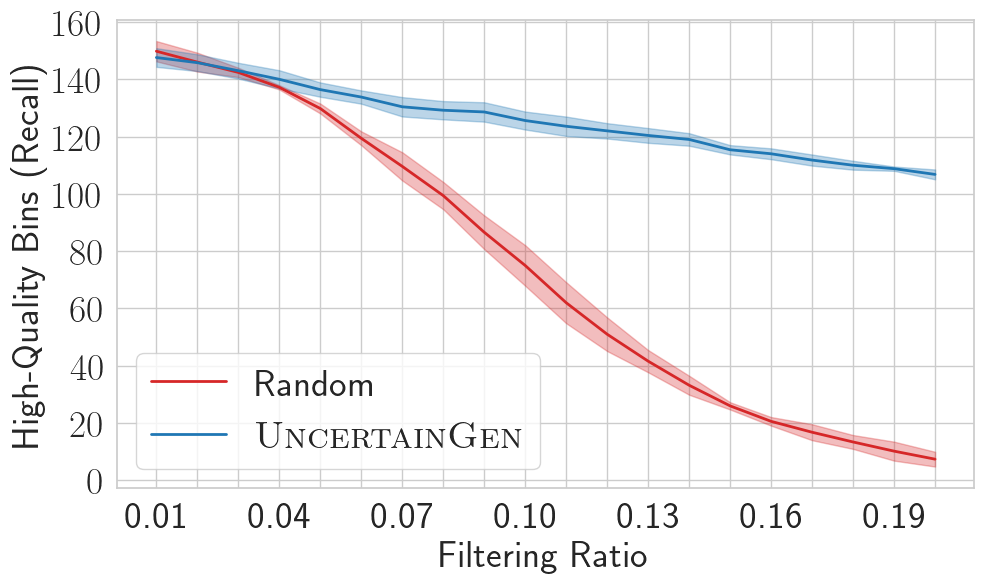

In [30]:
# Plot the single figure
dataset_name = "reference"
dataset_id = 5
strategies = ["random", "cov"]
seed_values = [1, 2, 3, 4, 5]


# Read the results
results = dict()
for seed in seed_values:

    # Define model name
    file_name = f"k=4_d=256_negperpos=200_maxseq=100000_epoch=25_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed={seed}_factortest.model_id={dataset_id}.pkl"
    # Define file path
    file_path = os.path.join(os.getcwd(), "results", "ablation", "filtering", dataset_name, file_name)

    with open(file_path, 'rb') as f:
        results[seed] = pkl.load(f)

# In the result files, indices correspond to the ratios varying from 0.01 up to 0.5, with increment of 0.01
max_ratio_index = 20
# Get the filter ratios
filter_ratios = results[seed_values[0]]['ours'][dataset_name][dataset_id]["random"]['filter_ratios'][:max_ratio_index]
# Scores are stored in a matrix of size (the number of filtering ratios x 9) where 9 is the bin quality thresholds
random_recall_scores = np.asarray(
    [np.asarray(results[seed]['ours'][dataset_name][dataset_id]["random"]['recall'])[:max_ratio_index,-1] for seed in seed_values]
)
ours_recall_scores = np.asarray(
    [np.asarray(results[seed]['ours'][dataset_name][dataset_id]["cov"]['recall'])[:max_ratio_index, -1] for seed in seed_values]
)

random_recall_scores_avg, random_recall_scores_std  = random_recall_scores.mean(axis=0), random_recall_scores.std(axis=0)
ours_recall_scores_avg, ours_recall_scores_std = ours_recall_scores.mean(axis=0), ours_recall_scores.std(axis=0)

# Plot the figure
plt.figure(figsize=(10, 6))
plt.plot(filter_ratios, random_recall_scores_avg, label="Random", color=colors[0], linewidth=2)
plt.fill_between(filter_ratios, random_recall_scores_avg - random_recall_scores_std, random_recall_scores_avg + random_recall_scores_std, color=colors[0], alpha=0.3)
plt.plot(filter_ratios, ours_recall_scores_avg, label=r"\textsc{UncertainGen}", color=colors[1], linewidth=2)
plt.fill_between(filter_ratios, ours_recall_scores_avg - ours_recall_scores_std, ours_recall_scores_avg + ours_recall_scores_std, color=colors[1], alpha=0.3)
plt.xlabel("Filtering Ratio", fontsize=fontsize)
plt.ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
plt.xticks(filter_ratios, [f"{value:.2f}" if idx%3==0 else '' for idx, value in enumerate(filter_ratios)], fontsize=fontsize)
plt.yticks(fontsize=fontsize)
plt.legend(fontsize=fontsize)
plt.grid(True)
plt.tight_layout()
# plt.show()
plt.savefig(
    os.path.join(os.getcwd(), "figures", f"single_filtering_{dataset_name}_{dataset_id}.png"),
    dpi=300, bbox_inches='tight'
)


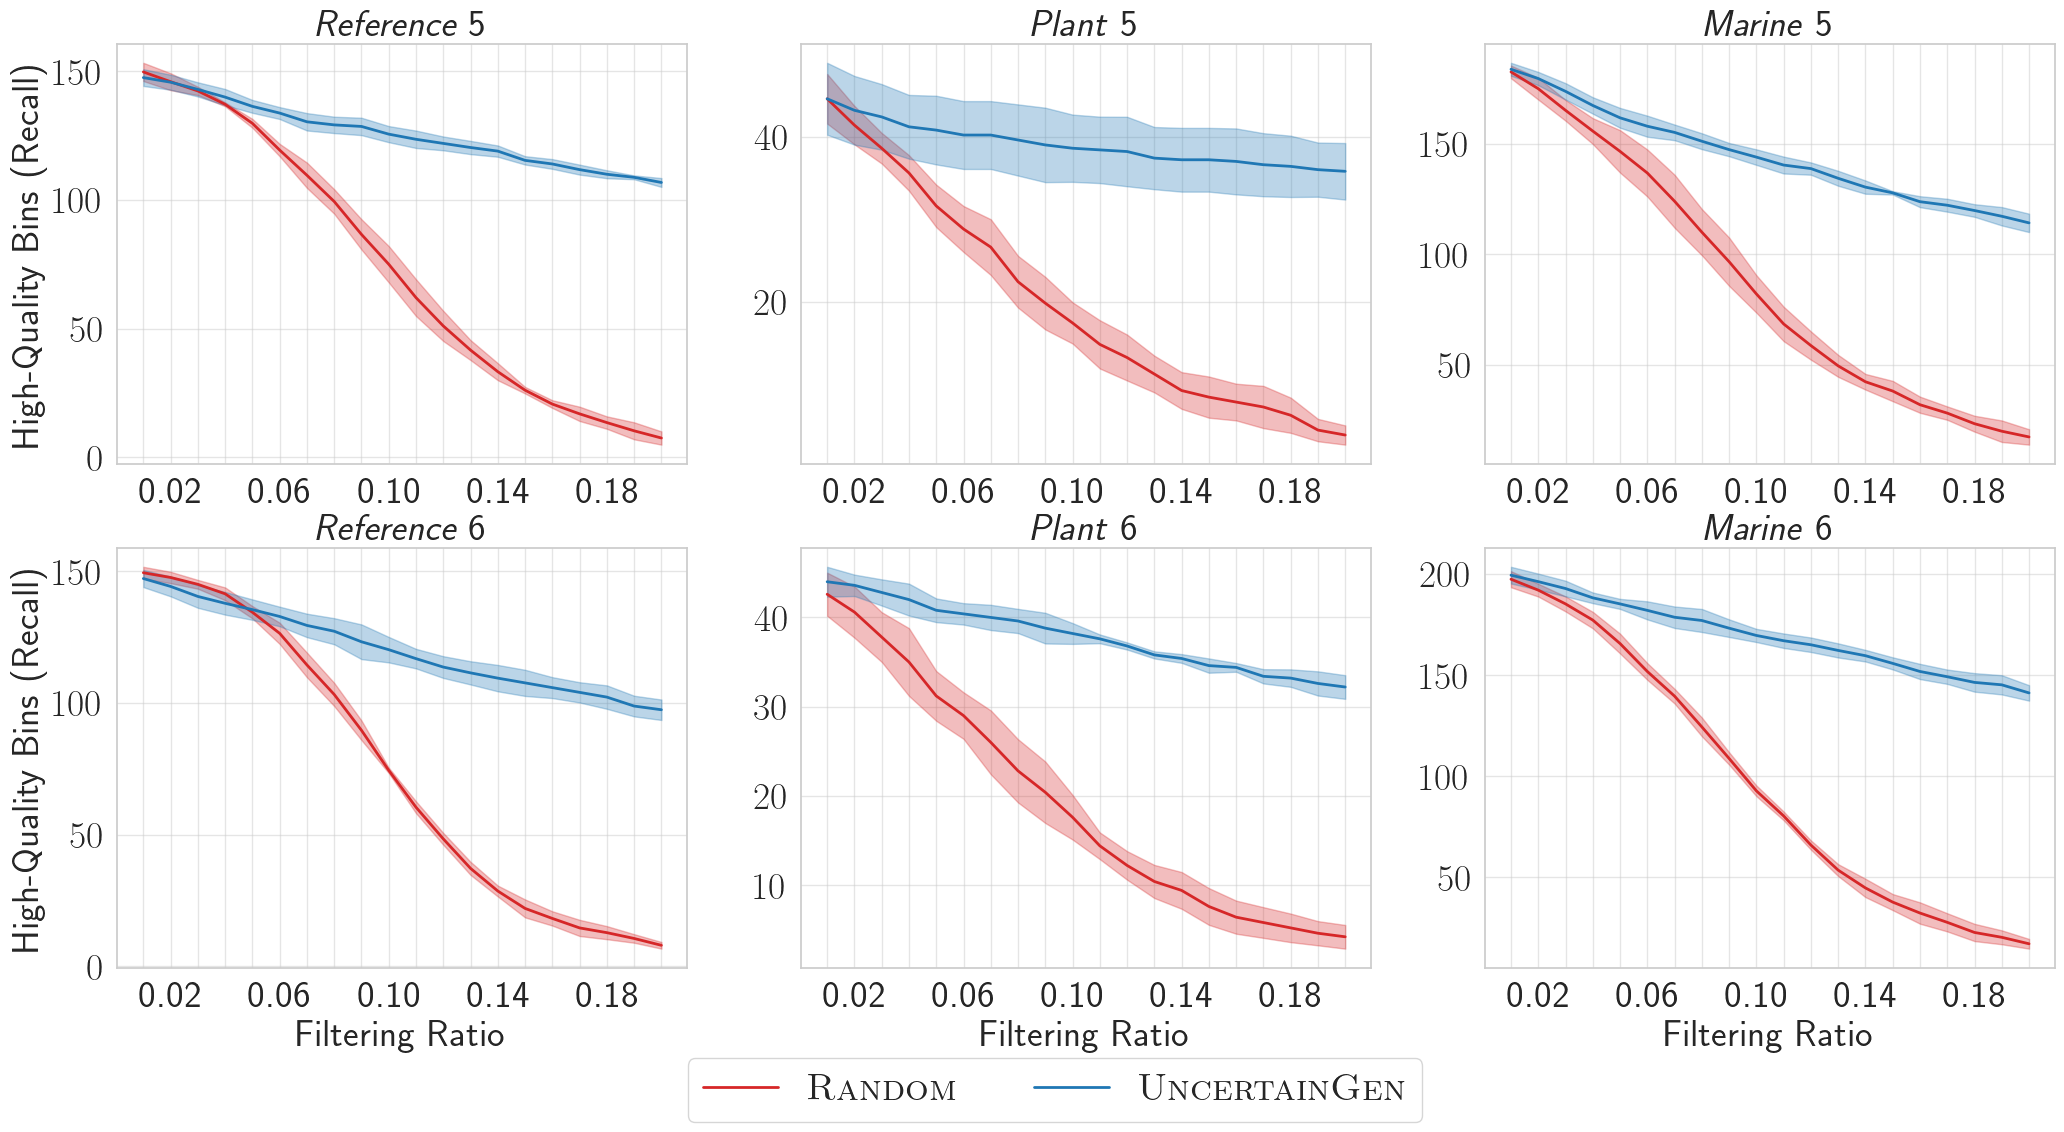

In [32]:
# Plot all figures

datasets = ["reference", "plant", "marine"]
dataset_ids = [5, 6]
strategies = ["random", "cov"]
seed_values = [1, 2, 3, 4, 5]
dataset_name2label = {
    "reference": r"\textsl{Reference}", "plant": r"\textsl{Plant}", "marine": r"\textsl{Marine}"
}

# Read the results
results = dict()
for dataset_name in datasets:
    results[dataset_name] = dict()

    for dataset_id in dataset_ids:

        results[dataset_name][dataset_id] = dict()

        for seed in seed_values:

            results[dataset_name][dataset_id][seed] = dict()
            # Define model name
            file_name = f"k=4_d=256_negperpos=200_maxseq=100000_epoch=25_lr=0.001_batch=100000_loss=mahalanobis_strategy=var_only_seed={seed}_factortest.model_id={dataset_id}.pkl"
            # Define file path
            file_path = os.path.join(os.getcwd(), "results", "ablation", "filtering", dataset_name, file_name)
            # Read the file
            with open(file_path, 'rb') as f:
                results[dataset_name][dataset_id][seed] = pkl.load(f)


max_ratio_index = 20
# Plot the histograms side by side
fig, axes = plt.subplots(2, 3, figsize=(25, 12))
# Get the filter ratios
temp_dataset_name = list(results.keys())[0]
filter_ratios = results[temp_dataset_name][dataset_id][seed_values[0]]['ours'][temp_dataset_name][dataset_id]["random"]['filter_ratios'][:max_ratio_index]

for i, dataset_name in enumerate(datasets):
    for j, dataset_id in enumerate(dataset_ids):

        random_recall_scores = np.asarray(
            [np.asarray(results[dataset_name][dataset_id][seed]['ours'][dataset_name][dataset_id]["random"]['recall'])[:max_ratio_index,-1] for seed in seed_values]
        )
        ours_recall_scores = np.asarray(
            [np.asarray(results[dataset_name][dataset_id][seed]['ours'][dataset_name][dataset_id]["cov"]['recall'])[:max_ratio_index,-1] for seed in seed_values]
        )
        random_recall_scores_avg, random_recall_scores_std = random_recall_scores.mean(axis=0), random_recall_scores.std(axis=0)
        ours_recall_scores_avg, ours_recall_scores_std = ours_recall_scores.mean(axis=0), ours_recall_scores.std(axis=0)

        ###
        rl, = axes[j, i].plot(filter_ratios, random_recall_scores_avg, label=r"\textsc{Random}", color=colors[0], linewidth=2)
        axes[j, i].fill_between(
            filter_ratios, random_recall_scores_avg-random_recall_scores_std, random_recall_scores_avg+random_recall_scores_std, color=colors[0], alpha=0.3
        )
        ml, = axes[j, i].plot(filter_ratios, ours_recall_scores_avg, label=r"\textsc{UncertainGen}", color=colors[1], linewidth=2)
        axes[j, i].fill_between(
            filter_ratios, ours_recall_scores_avg-ours_recall_scores_std, ours_recall_scores_avg+ours_recall_scores_std, color=colors[1], alpha=0.3
        )
        axes[j, i].set_title(f"{dataset_name2label[dataset_name]} {dataset_id}", fontsize=fontsize)
        if i == 0:
            axes[j, i].set_ylabel("High-Quality Bins (Recall)", fontsize=fontsize)
        if j == 1:
            axes[j, i].set_xlabel(r"Filtering Ratio", fontsize=fontsize)
        axes[j, i].tick_params(axis='x', labelsize=fontsize)
        axes[j, i].tick_params(axis='y', labelsize=fontsize)
        axes[j, i].set_xticks(filter_ratios, [f"{value:.2f}" if idx%4==1 else '' for idx, value in enumerate(filter_ratios)], fontsize=fontsize)
        # axes[0, 0].legend(fontsize=fontsize)
        axes[j, i].grid(True, alpha=0.5)

# Add the legend out of the plot and below in one line
legend = fig.legend(
    handles=[rl, ml], labels=[r"\textsc{Random}", r"\textsc{UncertainGen}",],
    loc='upper center', bbox_to_anchor=(0.5, 0.05), ncol=2, fontsize=fontsize
)
# plt.show()
plt.savefig(
    os.path.join(os.getcwd(), "figures", f"all_filtering.png"), dpi=300, bbox_inches='tight'
)
